# Lab: Build a dense variational autoencoder for faces

**Time:** 90–120 minutes  
**Prerequisites:** PyTorch, linear layers, probability basics, and gradient descent

In this lab you will turn an image into a *distribution* in latent space, sample from
that distribution with the reparameterization trick, and train a decoder using the
VAE objective. The network is deliberately fully connected: convolution is useful
for images, but it is not what makes a model a VAE.

By the end, you should be able to:

- distinguish a deterministic autoencoder from a VAE;
- parameterize $q_\phi(z\mid x)$ with $\mu$ and $\log\sigma^2$;
- implement $z=\mu+\sigma\odot\epsilon$ without breaking backpropagation;
- combine reconstruction and KL-divergence terms; and
- generate new faces by sampling $z\sim\mathcal N(0,I)$.


**Jiwak — completed revision.** Original dense architecture and checks retained. Measured CPU experiment: fixed 2,000/500-image subsets of the seeded LFW split, five epochs per model. This limited-data run is reported as such; it does not claim full-dataset convergence.


## 1. Environment and LFW data (10 minutes)

This notebook runs both on Kaggle and locally.

**On Kaggle:** create a notebook, choose **Add Input**, search for `LFW Dataset`, and
attach the dataset whose mounted folder is `/kaggle/input/lfw-dataset`. Upload this
notebook or open it from the course repository, then choose a GPU accelerator if one
is available. No path edit should be necessary.

**Locally:** download and extract LFW so the directory contains person folders and
`.jpg` files. Then either:

1. set the environment variable `LFW_DATASET_PATH` to the extracted directory; or
2. edit `LOCAL_DATASET_PATH` in the next cell.

The path may point either directly to `lfw-deepfunneled` or to a parent directory;
the discovery code searches below it. The notebook fails early with a useful message
if no images are found.


In [1]:
# Kaggle images normally include these packages. For a minimal local environment:
# %pip install torch torchvision matplotlib pandas scikit-learn pillow

import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(2)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGE_SIZE = 45
CHANNELS = 3
INPUT_DIM = CHANNELS * IMAGE_SIZE * IMAGE_SIZE
LATENT_DIM = 100
BATCH_SIZE = 64
EPOCHS = 5
LEARNING_RATE = 1e-3
BETA = 1.0
NUM_WORKERS = 2 if torch.cuda.is_available() else 0

# Change only this line for a local setup if LFW_DATASET_PATH is not set.
LOCAL_DATASET_PATH = Path("lfwfunneled/lfw_funneled")

print(f"Running on {DEVICE}")

# Locate the workspace data from either this notebook or its submission copy.
WORKSPACE_ROOT = next(root for root in (Path.cwd(), *Path.cwd().parents)
                      if (root / "lfwfunneled/lfw_funneled").exists())
LOCAL_DATASET_PATH = WORKSPACE_ROOT / "lfwfunneled/lfw_funneled"
TRAIN_LIMIT = 2000
VAL_LIMIT = 500
print(f"Limited-data CPU run: {TRAIN_LIMIT} train / {VAL_LIMIT} validation, {EPOCHS} epochs")


Running on cpu
Limited-data CPU run: 2000 train / 500 validation, 5 epochs


In [2]:
def resolve_lfw_root():
    env_path = os.environ.get("LFW_DATASET_PATH")
    candidates = []
    if env_path:
        candidates.append(Path(env_path).expanduser())
    if Path("/kaggle/input").exists():
        candidates.extend([
            Path("/kaggle/input/lfw-dataset/lfw-deepfunneled/lfw-deepfunneled"),
            Path("/kaggle/input/lfw-dataset"),
        ])
    candidates.extend([
        LOCAL_DATASET_PATH.expanduser(),
        Path("lfw-deepfunneled"),
    ])

    for root in candidates:
        if root.exists() and next(root.rglob("*.jpg"), None) is not None:
            return root
    checked = "\n".join(f"  - {path}" for path in candidates)
    raise FileNotFoundError(
        "No LFW .jpg files were found. Attach lfw-dataset on Kaggle, set "
        "LFW_DATASET_PATH, or edit LOCAL_DATASET_PATH. Checked:\n" + checked
    )


DATASET_ROOT = resolve_lfw_root()
image_paths = sorted(DATASET_ROOT.rglob("*.jpg"))
image_df = pd.DataFrame({
    "path": image_paths,
    "person": [path.parent.name for path in image_paths],
})

# Preserve the original notebook's balancing choice: remove identities with 25+
# photographs so a few celebrities do not dominate reconstruction training.
image_df = image_df.groupby("person", group_keys=False).filter(lambda rows: len(rows) < 25)
image_df = image_df.reset_index(drop=True)

print(f"Dataset root: {DATASET_ROOT}")
print(f"Using {len(image_df):,} images from {image_df['person'].nunique():,} people")
image_df.head()


Dataset root: /home/jiwak/GenAi_Notes/Gen_AI_Lab/lfwfunneled/lfw_funneled
Using 10,645 images from 5,707 people
Out[2]: 
                                                path           person
0  /home/jiwak/GenAi_Notes/Gen_AI_Lab/lfwfunneled...          AJ_Cook
1  /home/jiwak/GenAi_Notes/Gen_AI_Lab/lfwfunneled...         AJ_Lamas
2  /home/jiwak/GenAi_Notes/Gen_AI_Lab/lfwfunneled...    Aaron_Eckhart
3  /home/jiwak/GenAi_Notes/Gen_AI_Lab/lfwfunneled...      Aaron_Guiel
4  /home/jiwak/GenAi_Notes/Gen_AI_Lab/lfwfunneled...  Aaron_Patterson


Actual train / validation sizes: 2000 500


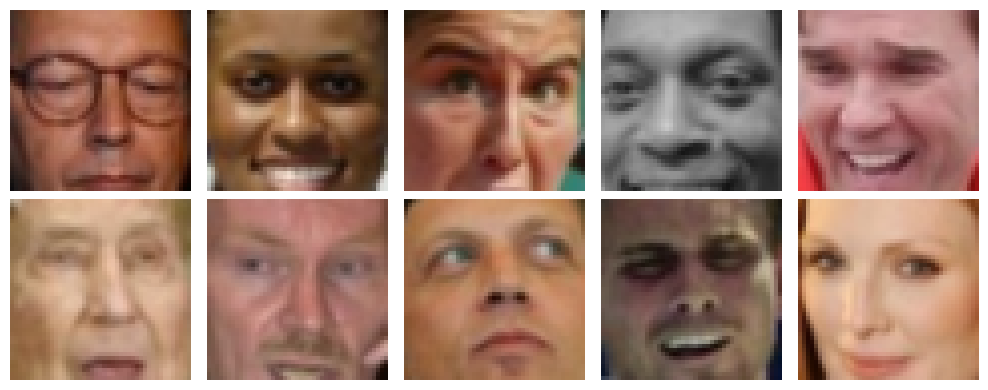

In [3]:
class FaceDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        path = self.dataframe.loc[index, "path"]
        with Image.open(path) as image:
            image = image.convert("RGB")
            # LFW deep-funneled images are 250x250. This reproduces the original
            # notebook's central crop while remaining safe for other image sizes.
            width, height = image.size
            margin_x = min(80, max(0, (width - 1) // 3))
            margin_y = min(80, max(0, (height - 1) // 3))
            image = image.crop((margin_x, margin_y, width - margin_x, height - margin_y))
            return self.transform(image)


transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),  # pixel values in [0, 1]
])

train_df, val_df = train_test_split(image_df, test_size=0.2, random_state=SEED)
# Fixed subsets of the original seeded split; no validation image enters training.
train_df = train_df.sample(n=min(TRAIN_LIMIT, len(train_df)), random_state=SEED)
val_df = val_df.sample(n=min(VAL_LIMIT, len(val_df)), random_state=SEED)
train_dataset = FaceDataset(train_df, transform)
val_dataset = FaceDataset(val_df, transform)

loader_args = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")
train_loader = DataLoader(train_dataset, shuffle=True, **loader_args)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_args)

# Cache transformed images once; every beta sees the same images and crop.
train_dataset = torch.utils.data.TensorDataset(torch.stack([train_dataset[i] for i in range(len(train_dataset))]))
val_dataset = torch.utils.data.TensorDataset(torch.stack([val_dataset[i] for i in range(len(val_dataset))]))
# TensorDataset wraps tensors in tuples; use its tensor directly to keep template batches unchanged.
train_dataset = train_dataset.tensors[0]
val_dataset = val_dataset.tensors[0]
train_loader = DataLoader(train_dataset, shuffle=True, **loader_args)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_args)
print("Actual train / validation sizes:", len(train_dataset), len(val_dataset))
faces = next(iter(train_loader))
assert faces.ndim == 4 and faces.shape[1:] == (3, 45, 45)
assert 0 <= faces.min() and faces.max() <= 1

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for face, axis in zip(faces[:10], axes.flat):
    axis.imshow(face.permute(1, 2, 0))
    axis.axis("off")
plt.tight_layout()


## 2. From autoencoder to VAE (10 minutes)

A deterministic autoencoder maps $x$ to one vector $z$. A VAE encoder instead
describes a diagonal Gaussian approximate posterior:

$$q_\phi(z\mid x)=\mathcal N\left(\mu_\phi(x),\operatorname{diag}(\sigma_\phi^2(x))\right).$$

We predict `logvar` rather than variance because it may take any real value and is
numerically convenient. For a batch of `N` images and `LATENT_DIM = 100`, answer:

1. What are the shapes of `mu`, `logvar`, and `z`?
2. Why must the final `mu` and `logvar` layers have no ReLU?
3. Why does directly drawing `z` from a distribution parameterized by the encoder
   make ordinary backpropagation difficult?

Write your answers in a new Markdown cell.

### Section 2 answers

1. `mu`, `logvar`, and sampled `z` each have shape `[N, 100]`; a batch has one diagonal Gaussian per face.
2. Means must allow negative as well as positive locations. Log-variance must also allow negative values (variance below one). ReLU would restrict both distributions unnecessarily; the two heads are linear.
3. A plain random draw does not expose an ordinary differentiable calculation connecting encoder parameters to the realized sample. Reparameterization writes `z = mu + exp(0.5 * logvar) * eps`, with parameter-independent standard-normal `eps`; gradients can then reach both encoder heads through tensor operations.


## 3. Implement the probabilistic encoder (25 minutes)

**TODO 1:** Add two linear heads that map the shared 1000-unit representation to
`LATENT_DIM`: one for `mu` and one for `logvar`.

**TODO 2:** Implement the reparameterization trick. Compute
$\sigma=\exp(\tfrac12\log\sigma^2)$, draw $\epsilon$ with `torch.randn_like`, and
return $\mu+\sigma\epsilon$.

**TODO 3:** Complete `forward`: encode, sample, decode, and return
`reconstruction, mu, logvar`. The decoder returns probabilities in `[0, 1]`, so its
last operation is a sigmoid.


In [4]:
class DenseFaceVAE(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, latent_dim=LATENT_DIM):
        super().__init__()

        self.input_dim = input_dim
        self.latent_dim = latent_dim

        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 1500),
            nn.ReLU(),
            nn.Linear(1500, 1000),
            nn.ReLU(),
        )

        # TODO 1: Mean and log-variance heads
        self.mu_head = nn.Linear(1000, latent_dim)
        self.logvar_head = nn.Linear(1000, latent_dim)

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 1000),
            nn.ReLU(),
            nn.Linear(1000, 1500),
            nn.ReLU(),
            nn.Linear(1500, input_dim),
            nn.Sigmoid(),
        )

    def encode(self, x):
        features = self.encoder(x.flatten(start_dim=1))

        mu = self.mu_head(features)
        logvar = self.logvar_head(features)

        return mu, logvar

    def reparameterize(self, mu, logvar):
        # TODO 2
        sigma = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(sigma)

        z = mu + sigma * epsilon

        return z

    def decode(self, z):
        pixels = self.decoder(z)

        return pixels.view(
            -1,
            CHANNELS,
            IMAGE_SIZE,
            IMAGE_SIZE
        )

    def forward(self, x):
        # TODO 3
        mu, logvar = self.encode(x)

        z = self.reparameterize(mu, logvar)

        reconstruction = self.decode(z)

        return reconstruction, mu, logvar


In [5]:
# These checks give fast feedback before expensive training.
model = DenseFaceVAE().to(DEVICE)
test_batch = faces[:4].to(DEVICE)
reconstruction, mu, logvar = model(test_batch)

assert reconstruction.shape == test_batch.shape
assert mu.shape == logvar.shape == (4, LATENT_DIM)
assert reconstruction.min() >= 0 and reconstruction.max() <= 1

# Sampling should normally give different z values, while gradients still reach
# both distribution heads.
z1 = model.reparameterize(mu, logvar)
z2 = model.reparameterize(mu, logvar)
assert not torch.equal(z1, z2)
(z1.mean()).backward()
assert model.mu_head.weight.grad is not None
assert model.logvar_head.weight.grad is not None
model.zero_grad(set_to_none=True)
print("Model checks passed.")


Model checks passed.


## 4. Implement the negative ELBO (20 minutes)

For this Bernoulli observation model, minimize

$$
\mathcal L = \underbrace{\operatorname{BCE}(\hat x,x)}_{\text{reconstruction}}
+\beta\underbrace{D_{KL}\!\left(q_\phi(z\mid x)\,\|\,\mathcal N(0,I)\right)}_{\text{regularization}}.
$$

For a diagonal Gaussian,

$$D_{KL}=-\frac12\sum_j\left(1+\log\sigma_j^2-\mu_j^2-\exp(\log\sigma_j^2)\right).$$

**TODO 4:** Compute BCE and KL with `reduction="sum"`, then divide each by the
batch size so reported values are per image. Return total loss, detached
reconstruction loss, and detached KL loss. Do not detach the total loss.


In [6]:
def vae_loss(reconstruction, target, mu, logvar, beta=1.0):

    # Reconstruction loss
    reconstruction_loss = F.binary_cross_entropy(
        reconstruction,
        target,
        reduction="sum"
    )

    # KL divergence
    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    # Normalize per image
    batch_size = target.size(0)

    reconstruction_loss = reconstruction_loss / batch_size
    kl_loss = kl_loss / batch_size

    # Total VAE loss
    total_loss = reconstruction_loss + beta * kl_loss

    return (
        total_loss,
        reconstruction_loss.detach(),
        kl_loss.detach()
    )


In [7]:
# At mu=0 and logvar=0, q(z|x) equals the unit-normal prior, so KL must be zero.
dummy_x = torch.full((2, 3, 45, 45), 0.5, device=DEVICE)
dummy_mu = torch.zeros(2, LATENT_DIM, device=DEVICE)
dummy_logvar = torch.zeros_like(dummy_mu)
total, recon_term, kl_term = vae_loss(dummy_x, dummy_x, dummy_mu, dummy_logvar)
assert torch.isclose(kl_term, torch.tensor(0.0, device=DEVICE))
assert total.requires_grad is False  # dummy tensors do not require gradients

# With model outputs, the total must carry a gradient path.
reconstruction, mu, logvar = model(test_batch)
total, _, _ = vae_loss(reconstruction, test_batch, mu, logvar, beta=BETA)
assert total.requires_grad
print("Loss checks passed.")


Loss checks passed.


## 5. Train the VAE (20–30 minutes)

**TODO 5:** Complete one training step: move the batch to the device, clear old
gradients, run the model, compute the VAE loss, backpropagate, and update parameters.

The reconstruction term sums over 6075 pixels, whereas KL sums over 100 latent
dimensions, so their magnitudes will differ. Track them separately. Ten epochs are a
starting point; reduce `EPOCHS` for a smoke test or increase it for better faces.


In [8]:
def train_step(model, batch, optimizer, beta):

    # Move data to GPU/CPU
    batch = batch.to(DEVICE, non_blocking=True)

    # Clear previous gradients
    optimizer.zero_grad(set_to_none=True)

    # Forward pass
    reconstruction, mu, logvar = model(batch)

    # Calculate VAE loss
    total_loss, reconstruction_loss, kl_loss = vae_loss(
        reconstruction,
        batch,
        mu,
        logvar,
        beta
    )

    # Backpropagation
    total_loss.backward()

    # Update parameters
    optimizer.step()

    return (
        total_loss.item(),
        reconstruction_loss.item(),
        kl_loss.item()
    )


Epoch 01 | train 4036.94 | val 4021.44 | recon 4021.29 | KL 0.15
Epoch 02 | train 4011.78 | val 4007.23 | recon 4005.66 | KL 1.57
Epoch 03 | train 4001.79 | val 3979.62 | recon 3971.07 | KL 8.55
Epoch 04 | train 3985.60 | val 3966.17 | recon 3954.94 | KL 11.23
Epoch 05 | train 3958.93 | val 3952.88 | recon 3933.26 | KL 19.62


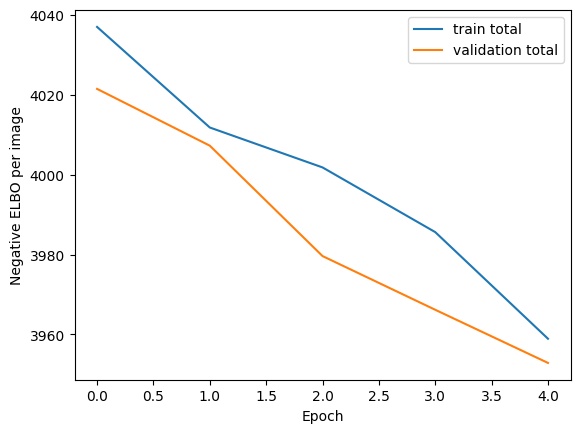

In [9]:
@torch.no_grad()
def evaluate(model, loader, beta):
    model.eval()
    totals = np.zeros(3, dtype=np.float64)
    examples = 0
    for batch in loader:
        batch = batch.to(DEVICE, non_blocking=True)
        reconstruction, mu, logvar = model(batch)
        values = vae_loss(reconstruction, batch, mu, logvar, beta)
        batch_size = batch.size(0)
        totals += np.array([value.item() for value in values]) * batch_size
        examples += batch_size
    return totals / examples


torch.manual_seed(SEED)
model = DenseFaceVAE().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
history = {"train_total": [], "val_total": [], "val_reconstruction": [], "val_kl": []}

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_total = 0.0
    seen = 0
    for batch in train_loader:
        total, reconstruction_term, kl_term = train_step(model, batch, optimizer, BETA)
        running_total += total * batch.size(0)
        seen += batch.size(0)

    val_total, val_reconstruction, val_kl = evaluate(model, val_loader, BETA)
    history["train_total"].append(running_total / seen)
    history["val_total"].append(val_total)
    history["val_reconstruction"].append(val_reconstruction)
    history["val_kl"].append(val_kl)
    print(
        f"Epoch {epoch:02d} | train {running_total / seen:.2f} | "
        f"val {val_total:.2f} | recon {val_reconstruction:.2f} | KL {val_kl:.2f}"
    )

plt.plot(history["train_total"], label="train total")
plt.plot(history["val_total"], label="validation total")
plt.xlabel("Epoch")
plt.ylabel("Negative ELBO per image")
plt.legend()
plt.show()


## 6. Inspect reconstructions (10 minutes)

For a repeatable reconstruction we decode the posterior mean rather than a random
sample. Compare identity, pose, colour, and fine detail. Dense networks discard
spatial structure when flattening, so some blur is expected.


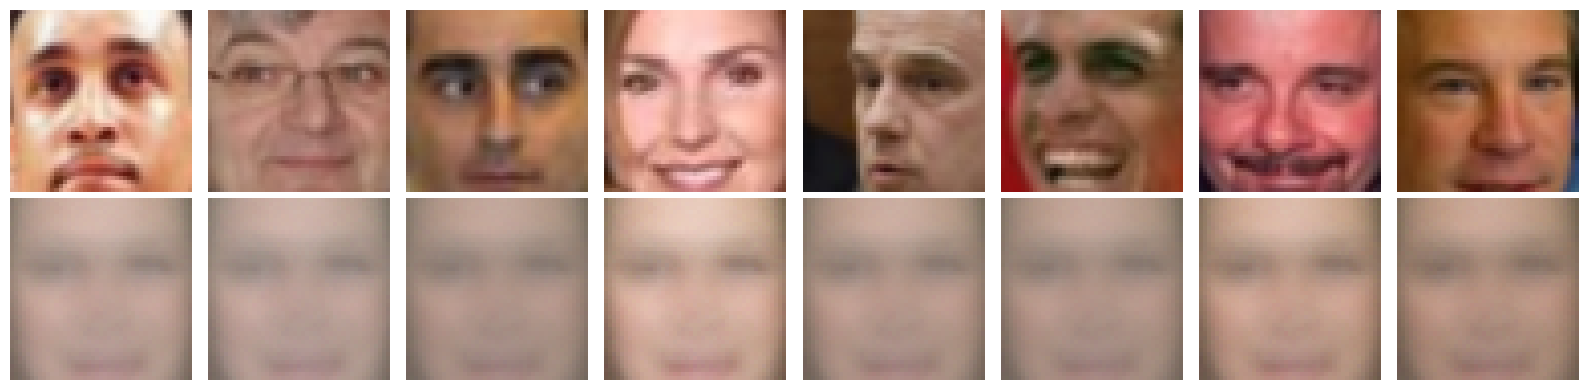

In [10]:
model.eval()
validation_faces = next(iter(val_loader))[:8].to(DEVICE)
with torch.no_grad():
    mu, _ = model.encode(validation_faces)
    reconstructed_faces = model.decode(mu)

originals = validation_faces.cpu()
reconstructed_faces = reconstructed_faces.cpu()
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for index in range(8):
    axes[0, index].imshow(originals[index].permute(1, 2, 0))
    axes[1, index].imshow(reconstructed_faces[index].permute(1, 2, 0).clamp(0, 1))
    axes[0, index].axis("off")
    axes[1, index].axis("off")
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed")
plt.tight_layout()


## 7. Generate new faces (10 minutes)

Reconstruction conditions on an existing face. Generation does not: it draws from
the prior and sends those latent vectors directly to the decoder.

**TODO 6:** Sample 10 latent vectors from $\mathcal N(0,I)$ on `DEVICE`, decode them,
and store the result in `generated_faces`. Then run the visualization cell.


In [11]:
model.eval()
with torch.no_grad():
    prior_generator = torch.Generator(device=DEVICE).manual_seed(SEED)
    fixed_prior = torch.randn(10, LATENT_DIM, generator=prior_generator, device=DEVICE)
    generated_faces = model.decode(fixed_prior)


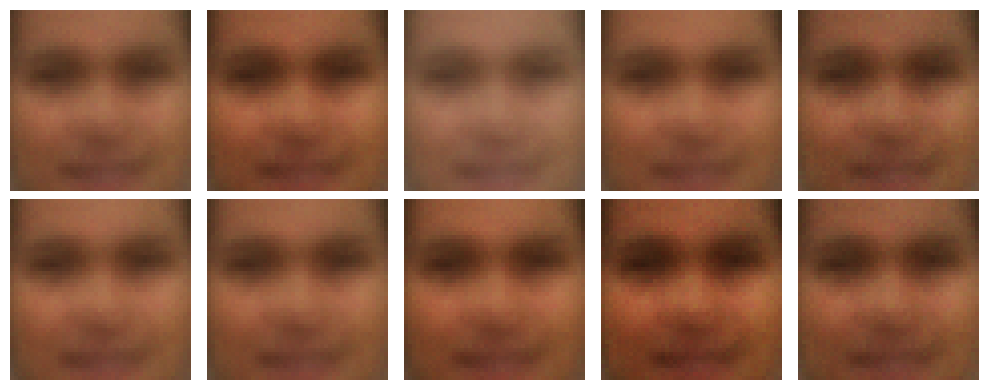

In [12]:
assert generated_faces.shape == (10, 3, 45, 45)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for face, axis in zip(generated_faces.cpu(), axes.flat):
    axis.imshow(face.permute(1, 2, 0).clamp(0, 1))
    axis.axis("off")
plt.tight_layout()


## 8. Experiment: what beta controls

Two fresh models used the same original dense architecture, seed 42, 2,000 training faces, 500 validation faces, batch size 64, Adam at 0.001, and five epochs. The image split and cached transformations were identical. Batch-order generators were reset for each model, evaluation used a fixed random seed, and both prior grids decode the same ten unit-normal vectors. The following executed cell contains the numerical results and grids.

| Beta | Validation reconstruction BCE/image | Validation KL/image | Prior-sample observations |
|---:|---:|---:|---|
| 0 | 3904.57 | 84.69 | Dark reddish/brown faces with weak eye/nose structure; the ten samples are very similar and blurred. |
| 4 | 3961.20 | 2.59 | Lighter, more consistent face-like structure, with eye shadows and noses; still very blurred with limited identity variation. |

### Section 8 answers

1. At beta=0, KL has no cost in the objective, so the encoder can place posterior codes wherever reconstruction benefits. Here validation reconstruction BCE is 3904.57 and KL is 84.69 per image. Its dark, similar prior samples contrast with the better input-conditioned reconstruction objective: sampling N(0,I) need not visit useful posterior codes.
2. At beta=4, validation KL falls to 2.59 while reconstruction BCE increases to 3961.20. The prior samples have a more consistent face-like appearance than beta=0, but remain blurred and similar to one another; this small five-epoch run does not show sharp or diverse generation. Increasing regularization trades some reconstruction fidelity for a posterior closer to the sampling prior. Low KL alone does not demonstrate that all latent dimensions carry useful information, and these two beta settings do not establish an optimal beta.
3. The VAE objective only needs differentiable functions that produce distribution parameters and decode samples; fully connected layers meet that requirement. Flattening the 3 × 45 × 45 image gives 6,075 input features, so this dense model has large weight matrices and does not share filters across nearby image locations. It lacks the spatial locality and translation-related inductive bias of convolutions and scales poorly to larger images.

The five-epoch beta=1 main run reduced validation total loss from 4021.44 to 3952.88 per image, and includes reconstructions and ten prior samples above. These numerical and visual results are from the limited-data run described here, rather than a claim of full-dataset convergence.


beta=0 epoch=1: reconstruction=4007.36, KL=71.22
beta=0 epoch=2: reconstruction=3940.68, KL=65.74
beta=0 epoch=3: reconstruction=3925.02, KL=85.09
beta=0 epoch=4: reconstruction=3903.92, KL=83.35
beta=0 epoch=5: reconstruction=3904.57, KL=84.69
beta=4 epoch=1: reconstruction=4015.32, KL=0.04
beta=4 epoch=2: reconstruction=4007.35, KL=0.58
beta=4 epoch=3: reconstruction=3994.59, KL=1.27
beta=4 epoch=4: reconstruction=3984.96, KL=1.46
beta=4 epoch=5: reconstruction=3961.20, KL=2.59
 beta  validation_reconstruction  validation_KL  validation_total
  0.0                3904.570629      84.685978       3904.570629
  4.0                3961.203811       2.589536       3971.561910
Out[13]: 2086


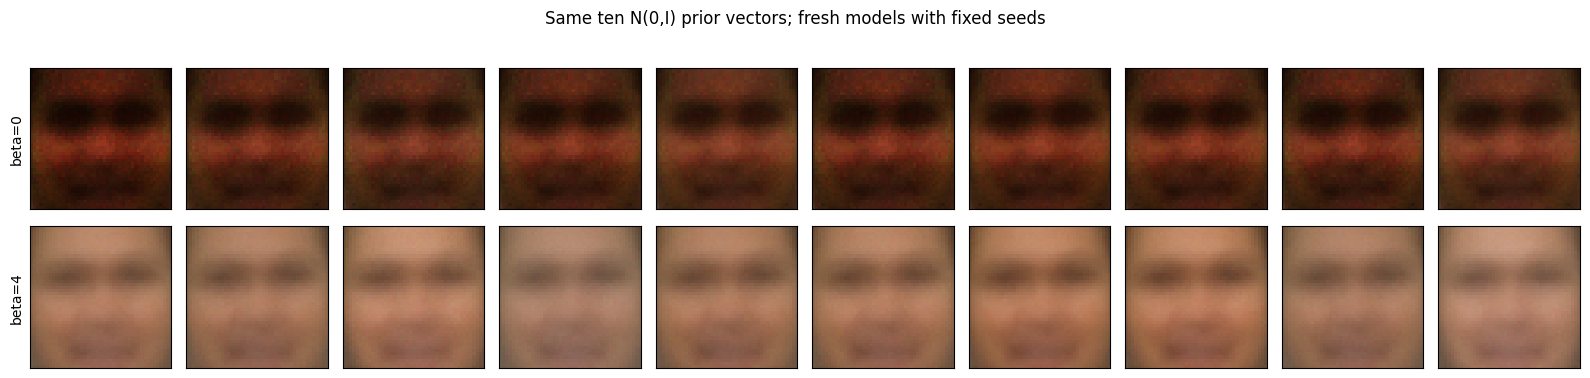

In [13]:
# Two fresh, controlled beta runs (the rubric requires at least two).
# Reset model seed and batch-order seed for both models; reuse fixed prior vectors.
beta_results = []
beta_samples = {}
beta_histories = {}
for beta in (0.0, 4.0):
    torch.manual_seed(SEED)
    candidate = DenseFaceVAE().to(DEVICE)
    candidate_optimizer = torch.optim.Adam(candidate.parameters(), lr=LEARNING_RATE)
    ordered_train = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                               generator=torch.Generator().manual_seed(SEED))
    candidate_history = []
    for epoch in range(1, EPOCHS + 1):
        candidate.train()
        for batch in ordered_train:
            train_step(candidate, batch, candidate_optimizer, beta)
        # Fixed stochastic evaluation seed gives comparable posterior draws.
        torch.manual_seed(SEED + 100)
        val_total, val_reconstruction, val_kl = evaluate(candidate, val_loader, beta)
        candidate_history.append([float(val_total), float(val_reconstruction), float(val_kl)])
        print(f"beta={beta:g} epoch={epoch}: reconstruction={val_reconstruction:.2f}, KL={val_kl:.2f}")
    beta_histories[str(beta)] = candidate_history
    beta_results.append({"beta": beta, "validation_reconstruction": float(val_reconstruction),
                         "validation_KL": float(val_kl), "validation_total": float(val_total)})
    with torch.no_grad():
        beta_samples[beta] = candidate.decode(fixed_prior).cpu()
    del candidate, candidate_optimizer
beta_df = pd.DataFrame(beta_results)
print(beta_df.to_string(index=False))
fig, axes = plt.subplots(2, 10, figsize=(16, 4))
for row, beta in enumerate((0.0, 4.0)):
    for col, face in enumerate(beta_samples[beta]):
        axes[row, col].imshow(face.permute(1, 2, 0).clamp(0, 1))
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
    axes[row, 0].set_ylabel(f"beta={beta:g}")
fig.suptitle("Same ten N(0,I) prior vectors; fresh models with fixed seeds")
plt.tight_layout()
plt.show()
import json
from pathlib import Path
(WORKSPACE_ROOT / "completed_labs/lab2_results.json").write_text(json.dumps({
    "train_images": len(train_dataset), "validation_images": len(val_dataset),
    "epochs": EPOCHS, "beta_results": beta_results, "beta_histories": beta_histories,
    "main_history": history}, indent=2))


## Submission and assessment

Submit the executed student notebook with:

- probabilistic encoder heads and correct tensor shapes (**1 mark**);
- reparameterization and forward pass, with checks passing (**2 marks**);
- reconstruction-plus-KL loss, with checks passing (**2 marks**);
- training step and recorded learning curves (**2 marks**);
- reconstructions and generated faces (**1 mark**); and
- the $\beta$ experiment and conceptual answers (**2 marks**).

**Total: 10 marks.**
